In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df=pd.read_csv("online_shoppers_intention.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Number of rows and columns:", df.shape)
print(df.columns.tolist())

Number of rows and columns: (12330, 18)
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [5]:
df.info()
print("Missing values in each column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [6]:
df["Revenue"].value_counts()
print(df["Revenue"].value_counts(normalize=True) * 100)

Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


In [7]:
purchase_counts = df["Revenue"].value_counts()

print("No Purchase:", purchase_counts.get(False, 0))
print("Purchase:", purchase_counts.get(True, 0))
print("Total Sessions:", len(df))

No Purchase: 10422
Purchase: 1908
Total Sessions: 12330


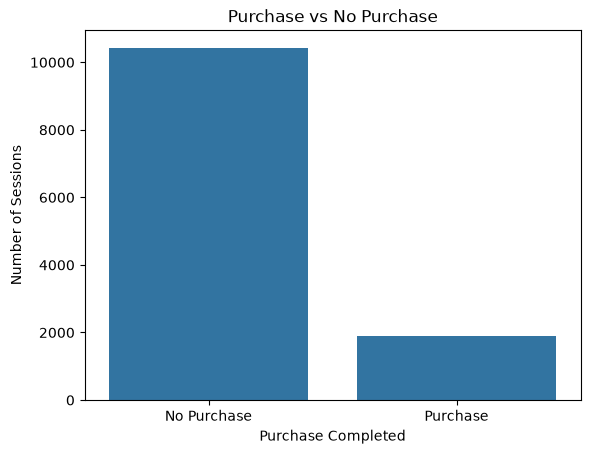

In [8]:
sns.countplot(data=df, x="Revenue")

plt.title("Purchase vs No Purchase")
plt.xlabel("Purchase Completed")
plt.ylabel("Number of Sessions")
plt.xticks([0, 1], ["No Purchase", "Purchase"])
plt.show()

In [10]:
df.describe()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [11]:
df.groupby("Revenue")[
    ["Administrative", "Informational", "ProductRelated",
     "Administrative_Duration", "Informational_Duration",
     "ProductRelated_Duration"]
].mean().round(2)

,Administrative,Informational,ProductRelated,Administrative_Duration,Informational_Duration,ProductRelated_Duration
Revenue,,,,,,
False,2.12,0.45,28.71,73.74,30.24,1069.99
True,3.39,0.79,48.21,119.48,57.61,1876.21


In [12]:
print("Months:")
print(df["Month"].value_counts())

print("\nVisitor Types:")
print(df["VisitorType"].value_counts())

print("\nWeekend:")
print(df["Weekend"].value_counts())

Months:
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

Visitor Types:
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

Weekend:
Weekend
False    9462
True     2868
Name: count, dtype: int64


In [14]:
# Remove PageValues to reduce the risk of target leakage
X = df.drop(columns=["Revenue", "PageValues"])

# Target variable
y = df["Revenue"].astype(int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.value_counts())

Input shape: (12330, 16)
Target shape: (12330,)

Input columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Target values:
Revenue
0    10422
1     1908
Name: count, dtype: int64


In [15]:
categorical_cols = X.select_dtypes(
    include=["object", "str", "bool"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['Month', 'VisitorType', 'Weekend']
Numerical columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


In [16]:
#Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training input shape: (9864, 16)
Testing input shape: (2466, 16)

Training target distribution:
Revenue
0    8338
1    1526
Name: count, dtype: int64

Testing target distribution:
Revenue
0    2084
1     382
Name: count, dtype: int64


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "str", "bool"]
).columns.tolist()

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
#Fit the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [19]:
#make the predictions
#predict the test data

y_pred = model.predict(X_test)

print("Actual values:", y_test.iloc[:10].tolist())
print("Predicted values:", y_pred[:10].tolist())

Actual values: [0, 0, 1, 0, 0, 0, 1, 0, 0, 0]
Predicted values: [0, 0, 1, 0, 0, 0, 0, 1, 1, 0]


Accuracy: 0.6148

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.92      0.59      0.72      2084
    Purchase       0.25      0.74      0.37       382

    accuracy                           0.61      2466
   macro avg       0.59      0.66      0.55      2466
weighted avg       0.82      0.61      0.67      2466



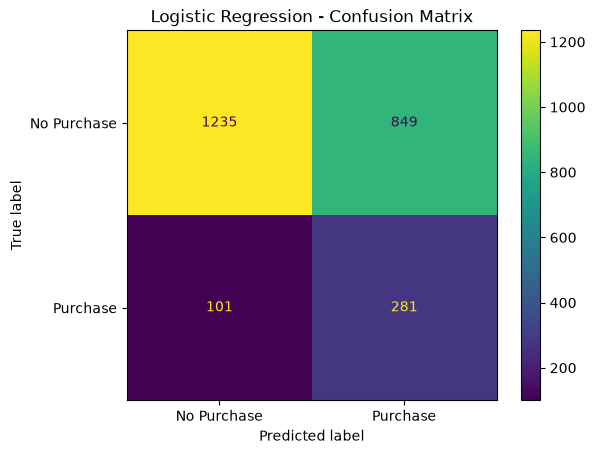

In [20]:
#calculate the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [21]:
#Train and evaluate decision tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

dt_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Results")
print("Accuracy:", round(accuracy_score(y_test, dt_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

Decision Tree Results
Accuracy: 0.629

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.63      0.74      2084
    Purchase       0.24      0.63      0.34       382

    accuracy                           0.63      2466
   macro avg       0.57      0.63      0.54      2466
weighted avg       0.80      0.63      0.68      2466



In [22]:
#Train and ecvaluate random forest

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

Random Forest Results
Accuracy: 0.7364

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.89      0.78      0.83      2084
    Purchase       0.29      0.50      0.37       382

    accuracy                           0.74      2466
   macro avg       0.59      0.64      0.60      2466
weighted avg       0.80      0.74      0.76      2466



In [23]:
#Comparison table

models = {
    "Logistic Regression": (model, model.predict(X_test)),
    "Decision Tree": (dt_model, dt_pred),
    "Random Forest": (rf_model, rf_pred)
}

results = []

for name, (trained_model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Purchase Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Purchase Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Purchase F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Purchase F1-Score",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Purchase Precision,Purchase Recall,Purchase F1-Score
0,Logistic Regression,0.6148,0.2487,0.7356,0.3717
1,Random Forest,0.7364,0.2938,0.5000,0.3702
2,Decision Tree,0.6290,0.2364,0.6257,0.3431


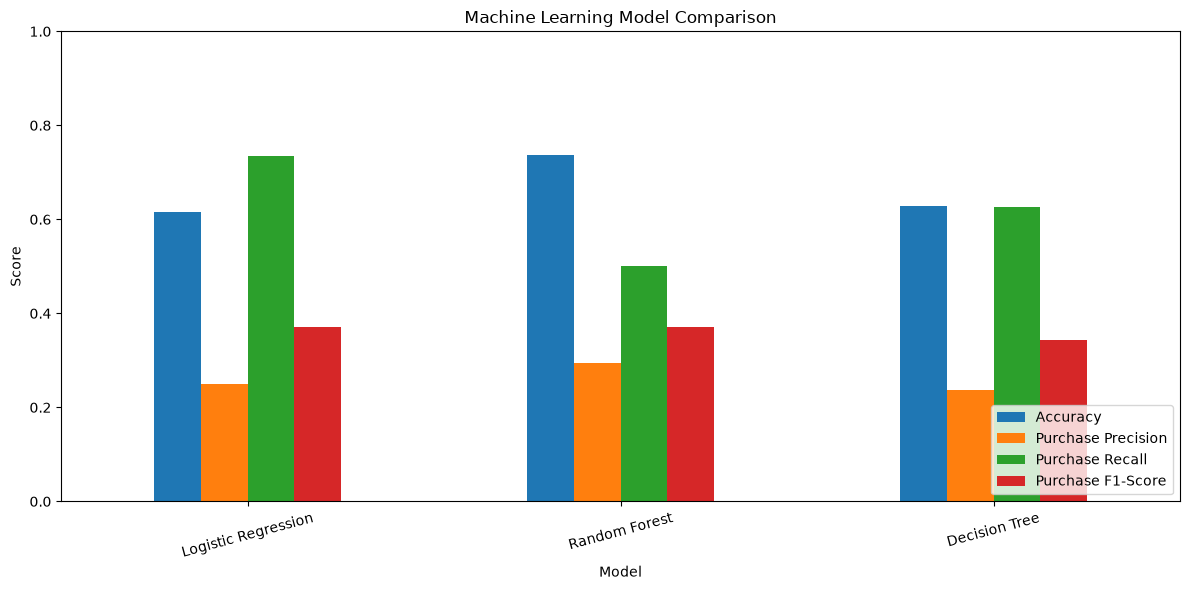

In [24]:
#Plot the comparison

results_df.set_index("Model")[
    ["Accuracy", "Purchase Precision",
     "Purchase Recall", "Purchase F1-Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get the probability of a purchase (class 1)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.3, 0.4, 0.5, 0.6]:
    pred = (rf_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Purchase Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Purchase Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "Purchase F1-Score": f1_score(
            y_test, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Purchase Precision,Purchase Recall,Purchase F1-Score
0,0.3,0.248,0.872,0.386
1,0.4,0.281,0.754,0.410
2,0.5,0.294,0.500,0.370
3,0.6,0.374,0.330,0.350


In [26]:
#Create training and validation sets

from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)

Training: (7891, 16)
Validation: (1973, 16)
Final test: (2466, 16)


In [27]:
#Select the threshold using validation data

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

rf_tuning_model = clone(rf_model)
rf_tuning_model.fit(X_fit, y_fit)

val_prob = rf_tuning_model.predict_proba(X_val)[:, 1]

validation_results = []

for threshold in [0.3, 0.4, 0.5, 0.6]:
    pred = (val_prob >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, pred, zero_division=0
        )
    })

validation_df = pd.DataFrame(validation_results)
validation_df.round(3)

,Threshold,Precision,Recall,F1-Score
0,0.3,0.238,0.875,0.374
1,0.4,0.268,0.734,0.393
2,0.5,0.306,0.531,0.388
3,0.6,0.396,0.393,0.395


Selected threshold: 0.4

Final Test Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.93      0.65      0.76      2084
    Purchase       0.28      0.75      0.41       382

    accuracy                           0.66      2466
   macro avg       0.61      0.70      0.59      2466
weighted avg       0.83      0.66      0.71      2466



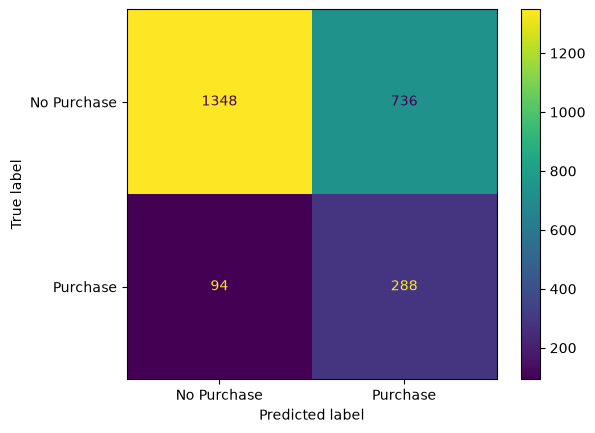

In [28]:
#Train the final model and evaluate once

best_threshold = 0.4  # Replace with your validation result

final_model = clone(rf_model)
final_model.fit(X_train, y_train)

test_prob = final_model.predict_proba(X_test)[:, 1]
final_pred = (test_prob >= best_threshold).astype(int)

print("Selected threshold:", best_threshold)

print("\nFinal Test Classification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=["No Purchase", "Purchase"]
)
plt.show()

In [29]:
#Save the trained model

import joblib

joblib.dump(final_model, "purchase_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [30]:
joblib.dump(best_threshold, "purchase_threshold.pkl")

['purchase_threshold.pkl']

In [31]:
import joblib

joblib.dump(final_model, "purchase_prediction_model.pkl")
joblib.dump(best_threshold, "purchase_threshold.pkl")

['purchase_threshold.pkl']